# 03 - Monthly seasonality
**Question:** in which months does each crop sell highest and lowest, and how reliable is that pattern?

**Method (ratio to centred moving average):**
1. For each crop and market, build a continuous monthly price series.
2. Divide each month's price by the centred 12-month moving average around it. This removes inflation (Malawi prices rise sharply year on year), so what is left is the seasonal swing. A value of 1.15 means the price was 15% above its local trend.
3. Take the median across markets for each year and month, then average across years. Rescale so each crop averages 1.0. That is the **seasonal index**.
4. **Consistency:** in what share of years did the three best months average higher than the three worst months?

Only series with at least 24 observations and near-complete windows contribute, so gappy periods drop out rather than being guessed.

In [1]:
import numpy as np
import pandas as pd
import plotly.express as px
from pathlib import Path

CLEAN = Path("..") / "clean_data"
OUT = Path("..") / "outputs"; OUT.mkdir(exist_ok=True)
MONTHS = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

prices = pd.read_csv(CLEAN / "prices_clean.csv", parse_dates=["date"])
tiers = pd.read_csv(CLEAN / "crop_mapping.csv").set_index("wfp_commodity")["history_tier"]
print(prices.shape)

(42784, 8)


In [2]:
W = np.r_[0.5, np.ones(11), 0.5] / 12          # centred 2x12 moving-average weights

def ratio_to_trend(s):
    # s: monthly series with NaN gaps. Returns price / centred 12-month moving average.
    v = s.values.astype(float)
    ma = np.full(len(v), np.nan)
    for i in range(6, len(v) - 6):
        win = v[i-6:i+7]
        ok = ~np.isnan(win)
        if ok.sum() >= 11:                      # allow at most 2 missing months in the window
            ma[i] = np.nansum(win * W) / W[ok].sum()
    return pd.Series(v / ma, index=s.index)

rows = []
for (crop, market), x in prices.groupby(["commodity", "market"]):
    s = x.set_index(x["date"].dt.to_period("M"))["price"]
    s = s.reindex(pd.period_range(s.index.min(), s.index.max(), freq="M"))
    if s.notna().sum() < 24:
        continue
    r = ratio_to_trend(s).dropna()
    rows.append(pd.DataFrame({"commodity": crop, "market": market,
                              "year": r.index.year, "month": r.index.month, "ratio": r.values}))
ratios = pd.concat(rows)
ratios = ratios[(ratios["ratio"] > 0.3) & (ratios["ratio"] < 3)]     # remove obvious data errors

ym = ratios.groupby(["commodity", "year", "month"])["ratio"].median().reset_index()
print(ratios.groupby("commodity").agg(observations=("ratio","size"), markets=("market","nunique"),
                                       years=("year","nunique")))

                      observations  markets  years
commodity                                         
Beans                         1983      105     12
Cassava                        334       34     16
Cowpeas                        884       81      5
Groundnuts (shelled)           780       52      9
Maize                         8727      118     22
Pigeon peas                    586       60      4
Rice                          1497       66     17
Sweet potatoes                 105       12      2


In [3]:
index = ym.groupby(["commodity", "month"])["ratio"].mean().unstack()
index = index.div(index.mean(axis=1), axis=0)
index.columns = MONTHS
index.round(2)

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
commodity,,,,,,,,,,,,
Beans,1.07,1.09,0.97,0.95,1.02,0.96,0.98,0.98,1.01,0.95,1.01,1.01
Cassava,1.15,1.08,0.99,0.93,0.93,0.95,0.95,0.98,0.96,0.96,1.04,1.08
Cowpeas,1.07,1.07,1.11,1.21,1.11,0.98,0.92,0.83,0.87,0.92,0.91,1.00
Groundnuts (shelled),1.10,1.11,1.11,1.03,0.92,0.93,0.91,0.93,0.99,0.95,0.97,1.05
Maize,1.18,1.19,1.16,0.97,0.83,0.83,0.89,0.92,0.96,0.98,1.02,1.08
Pigeon peas,1.05,1.12,1.19,1.27,1.20,0.89,0.76,0.78,0.90,0.87,0.93,1.03
Rice,1.04,1.07,1.07,1.04,1.01,0.98,0.94,0.95,0.97,0.96,0.97,0.99
Sweet potatoes,0.98,0.82,0.85,NaN,NaN,NaN,0.70,1.17,1.19,1.15,1.12,1.02


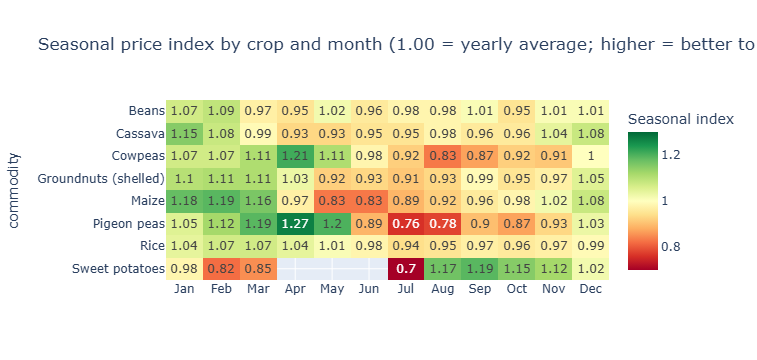

In [4]:
fig = px.imshow(index.round(2), text_auto=True, aspect="auto", color_continuous_scale="RdYlGn",
                color_continuous_midpoint=1.0,
                labels=dict(color="Seasonal index"),
                title="Seasonal price index by crop and month (1.00 = yearly average; higher = better to sell)")
fig.show()
fig.write_html(OUT / "seasonal_index_heatmap.html")

## Best months to sell, size of the swing, and how reliable it is

In [5]:
rows = []
for crop in index.index:
    s = index.loc[crop].dropna()
    best3, worst3 = s.nlargest(3).index.tolist(), s.nsmallest(3).index.tolist()
    yy = ym[ym["commodity"] == crop].pivot(index="year", columns="month", values="ratio")
    yy.columns = [MONTHS[m-1] for m in yy.columns]
    b = yy[[m for m in best3 if m in yy]].mean(axis=1)
    w = yy[[m for m in worst3 if m in yy]].mean(axis=1)
    diff = (b - w).dropna()
    rows.append({"crop": crop, "history": tiers.get(crop),
                 "best_months": ", ".join(best3), "worst_months": ", ".join(worst3),
                 "price_gain_best_vs_worst_%": round((s[best3].mean() / s[worst3].mean() - 1) * 100, 1),
                 "years_tested": len(diff), "years_pattern_held": int((diff > 0).sum()),
                 "months_covered": int(s.notna().sum())})
summary = pd.DataFrame(rows).sort_values("years_tested", ascending=False).reset_index(drop=True)
summary["consistency_%"] = (summary["years_pattern_held"] / summary["years_tested"] * 100).round(0)
summary.to_csv(OUT / "best_months_to_sell.csv", index=False)
summary

,crop,history,best_months,worst_months,price_gain_best_vs_worst_%,years_tested,years_pattern_held,months_covered,consistency_%
0,Maize,strong,"Feb, Jan, Mar","May, Jun, Jul",38.2,18,17,12,94.0
1,Rice,strong,"Feb, Mar, Apr","Jul, Aug, Oct",11.3,14,12,12,86.0
2,Cassava,strong,"Jan, Dec, Feb","May, Apr, Jun",17.7,10,9,12,90.0
3,Beans,strong,"Feb, Jan, May","Apr, Oct, Jun",11.0,7,6,12,86.0
4,Groundnuts (shelled),moderate,"Mar, Feb, Jan","Jul, May, Jun",20.7,5,5,12,100.0
5,Cowpeas,indicative,"Apr, May, Mar","Aug, Sep, Nov",31.4,1,1,12,100.0
6,Pigeon peas,indicative,"Apr, May, Mar","Jul, Aug, Oct",52.0,1,1,12,100.0
7,Sweet potatoes,indicative,"Sep, Aug, Oct","Jul, Feb, Mar",47.6,1,1,9,100.0


**How to read the table:** *price_gain_best_vs_worst_%* is the typical gain from selling in the three best months instead of the three worst. 
*years_tested* is how many years had enough data to test. Treat crops with 1 or 2 years tested as **indicative only**, because the pattern has not been verified.

## Does the pattern differ by region?

In [6]:
reg = prices[["market", "region"]].drop_duplicates("market").set_index("market")["region"]
ratios["region"] = ratios["market"].map(reg)

def regional(crop):
    x = (ratios[ratios["commodity"] == crop]
         .groupby(["region", "year", "month"])["ratio"].median().reset_index()
         .groupby(["region", "month"])["ratio"].mean().unstack())
    x = x.div(x.mean(axis=1), axis=0); x.columns = [MONTHS[m-1] for m in x.columns]
    return x

for crop in ["Maize", "Rice", "Beans"]:
    print(crop); display(regional(crop).round(2))

Maize


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
region,,,,,,,,,,,,
Central Region,1.18,1.19,1.19,1.00,0.84,0.83,0.88,0.91,0.94,0.96,1.01,1.07
Northern Region,1.14,1.20,1.23,1.09,0.87,0.82,0.86,0.90,0.91,0.95,0.99,1.05
Southern Region,1.20,1.19,1.12,0.88,0.78,0.83,0.87,0.95,0.99,1.02,1.06,1.11


Rice


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
region,,,,,,,,,,,,
Central Region,1.02,1.07,1.06,1.04,0.99,0.97,0.96,0.97,1.00,0.96,0.97,1.00
Northern Region,1.05,1.06,1.08,1.05,1.04,0.95,0.95,0.93,0.94,0.97,0.98,0.98
Southern Region,1.06,1.08,1.11,1.09,0.97,0.95,0.91,0.97,0.94,0.92,0.97,1.03


Beans


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
region,,,,,,,,,,,,
Central Region,1.07,1.10,0.94,0.91,1.02,0.97,0.98,1.01,1.01,0.98,0.99,1.02
Northern Region,1.13,1.16,1.06,0.91,1.07,0.90,0.91,0.92,0.98,0.93,1.03,1.00
Southern Region,1.06,1.07,1.00,1.01,1.03,0.99,0.97,0.97,0.98,0.92,0.99,1.01


## Individual years: did recent years follow the usual pattern?

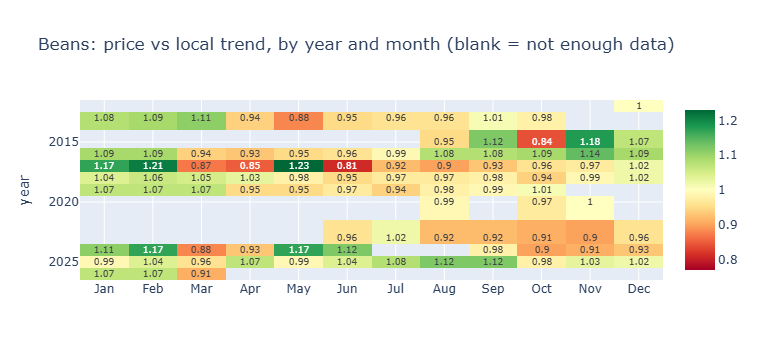

In [8]:
crop = "Beans"      # change to Rice, Beans, Cassava, ...
yr = ym[(ym["commodity"] == crop)].pivot(index="year", columns="month", values="ratio")
yr.columns = [MONTHS[m-1] for m in yr.columns]
fig = px.imshow(yr.round(2), text_auto=True, aspect="auto", color_continuous_scale="RdYlGn",
                color_continuous_midpoint=1.0, title=f"{crop}: price vs local trend, by year and month (blank = not enough data)")
fig.show()

## Limitations
- WFP prices are **retail market** prices, not farm-gate prices. A farmer will usually receive less than these figures.
- Years with data gaps (2022 for most crops, 2023 to 2024 for maize) drop out of the method, so **recent-year evidence is thin**.
- Cowpeas, pigeon peas and sweet potatoes have only 1 to 3 usable years: the pattern is a hint, not a result.
- A seasonal gain is not profit. Storing grain costs money and loses some to pests and spoilage, so the gain has to exceed those costs.
- Weather shocks and policy changes (such as export bans) can override the usual pattern in any given year.